## Import file và thư viện nè hihi

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))
from Ho_tro import Pipeline_of_project as pl
from Ho_tro import bio_utils as bu
from Ho_tro import task_utils as tu

In [10]:
import json
import time
from collections import Counter
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
import pickle
import numpy as np


import numpy as np
import feature_extractor as fe
import Model_CRF as mc          
import Model_HMM as mh  

MODEL_PATH_CRF = "./trained_model/crf_model.npz"             

LEARNING_RATE = 0.05
EPOCHS_MOI_DOT = 3                       # train 3 epoch rồi đánh giá dev một lần
SO_DOT_TOI_DA = 10                       # tối đa 10 đợt (30 epoch)
PATIENCE = 3                  # dev F1 không tăng sau 3 đợt liên tiếp thì dừng

In [3]:
import importlib
importlib.reload(pl)
importlib.reload(bu)
importlib.reload(fe)
importlib.reload(mc)
importlib.reload(tu)


<module 'Ho_tro.task_utils' from 'd:\\Học\\Môn Học Trên Trường\\NLP\\Project_cuối_kì\\Code\\Ho_tro\\task_utils.py'>

## 1. Lấy dữ liệu

In [4]:
paths = []
paths.append("..\..\Data\Dữ liệu Huấn Luyện\Train_Test_Dev_Anno4.json")

data_tong_hop, error = pl.pipeline_chuan_bi_data_training(paths)

X_train_2, Y_train_2 = tu.lay_dong(data_tong_hop, "train")
X_dev_2, Y_dev_2 = tu.lay_dong(data_tong_hop, "dev")

In [5]:
X_train_1, Y_train_1, error_train = tu.doc_du_lieu_mo("..\..\Data\Dữ liệu Huấn Luyện\Du_lieu_train.json")
X_dev_1, Y_dev_1, error_dev = tu.doc_du_lieu_mo("..\..\Data\Dữ liệu Huấn Luyện\Du_lieu_dev.json")

### Phân tích dữ liệu

In [7]:
dem_thuc_the = Counter(tag[2:] for dong in Y_train_1 for tag in dong if tag.startswith("B-"))

tong = sum(dem_thuc_the.values())
for loai, so_luong in dem_thuc_the.most_common():
    ti_le = so_luong / tong * 100
    print(f"Nhãn {loai} có {so_luong} thực thể  ({ti_le:.3f}%)")

print("-" * 50)
print(f"{'TỔNG CỘNG'} {tong} thực thể")

Nhãn SKILL có 3074 thực thể  (32.074%)
Nhãn DEGREE có 968 thực thể  (10.100%)
Nhãn SKILL_GROUP có 831 thực thể  (8.671%)
Nhãn POSITION có 793 thực thể  (8.274%)
Nhãn EXPERIENCE có 745 thực thể  (7.773%)
Nhãn BENEFIT có 640 thực thể  (6.678%)
Nhãn LOCATION có 635 thực thể  (6.626%)
Nhãn COMPANY có 613 thực thể  (6.396%)
Nhãn SALARY có 451 thực thể  (4.706%)
Nhãn DEADLINE có 426 thực thể  (4.445%)
Nhãn CERTIFICATE có 408 thực thể  (4.257%)
--------------------------------------------------
TỔNG CỘNG 9584 thực thể


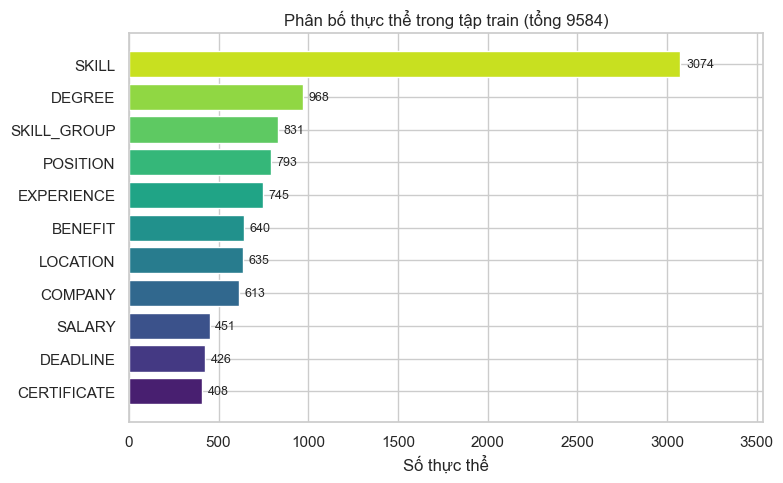

In [20]:
loai   = list(dem_thuc_the.keys())
so_luong = list(dem_thuc_the.values())

cap = sorted(zip(so_luong, loai))          
so_luong = [x[0] for x in cap]
loai     = [x[1] for x in cap]

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.barh(loai, so_luong,
               color=sns.color_palette("viridis", len(loai)))
for b, sl in zip(bars, so_luong):
    ax.text(b.get_width() + max(so_luong) * 0.01,
            b.get_y() + b.get_height() / 2,
            f"{sl}", va="center", fontsize=9)

ax.set_xlabel("Số thực thể")
ax.set_title(f"Phân bố thực thể trong tập train (tổng {sum(so_luong)})",
             fontsize=12)
ax.set_xlim(0, max(so_luong) * 1.15)       

plt.tight_layout()
plt.show()

In [11]:
do_dai       = [len(dong) for dong in X_train_1]
so_tt_moi_cau = [
    sum(1 for tag in dong if tag.startswith("B-"))
    for dong in Y_train_1
]
thong_ke = {
    "Số câu":                     len(do_dai),
    "Tổng token":                 sum(do_dai),
    "Tổng thực thể":              sum(so_tt_moi_cau),
    "TB token/câu":               f"{np.mean(do_dai):.1f}",
    "TB thực thể/câu":            f"{np.mean(so_tt_moi_cau):.2f}",
    "Token/câu — Min / Max":      f"{min(do_dai)} / {max(do_dai)}",
    "Thực thể/câu — Max":         max(so_tt_moi_cau),
    "Câu KHÔNG có thực thể":      sum(s == 0 for s in so_tt_moi_cau)
}

print(f"{'THỐNG KÊ TẬP TRAIN':^52}")
for k, v in thong_ke.items():
    print(f"  {k:<32}{str(v):>16}")


                 THỐNG KÊ TẬP TRAIN                 
  Số câu                                      5953
  Tổng token                                 57189
  Tổng thực thể                               9584
  TB token/câu                                 9.6
  TB thực thể/câu                             1.61
  Token/câu — Min / Max                     1 / 45
  Thực thể/câu — Max                            11
  Câu KHÔNG có thực thể                        955


In [12]:
from collections import Counter
dem_token = Counter(tag for dong in Y_train_1 for tag in dong)
tong_token = sum(dem_token.values())

for tag, sl in dem_token.most_common():
    print(f"{tag:<16} {sl:>7}  ({sl/tong_token*100:5.2f}%)")

O                  39059  (68.30%)
B-SKILL             3074  ( 5.38%)
I-LOCATION          2169  ( 3.79%)
I-DEGREE            1220  ( 2.13%)
I-BENEFIT           1180  ( 2.06%)
I-POSITION          1099  ( 1.92%)
B-DEGREE             968  ( 1.69%)
B-SKILL_GROUP        831  ( 1.45%)
B-POSITION           793  ( 1.39%)
B-EXPERIENCE         745  ( 1.30%)
I-SALARY             735  ( 1.29%)
I-EXPERIENCE         659  ( 1.15%)
B-BENEFIT            640  ( 1.12%)
B-LOCATION           635  ( 1.11%)
I-COMPANY            622  ( 1.09%)
B-COMPANY            613  ( 1.07%)
I-SKILL              462  ( 0.81%)
B-SALARY             451  ( 0.79%)
B-DEADLINE           426  ( 0.74%)
B-CERTIFICATE        408  ( 0.71%)
I-CERTIFICATE        242  ( 0.42%)
I-SKILL_GROUP        158  ( 0.28%)


## 3. Train mô hình CRF



### khởi tạo 

In [15]:
f_e = fe.FeatureExtractor(r"..\Kho_tri_thuc")
crf = mc.CRF(f_e, learning_rate=LEARNING_RATE)
print("số nhãn:", crf.so_nhan, "| số feature:", crf.so_feature)

số nhãn: 12 | số feature: 59


### Train

In [16]:
LICH_SU_PATH_CRF = r".\trained_model\lich_su_train.json"

lich_su = []
tot_nhat = {"f1": -1.0, "dot": 0, "trong_so": None}
so_dot_khong_tot_hon = 0
so_epoch_da_train = 0

for dot in range(1, SO_DOT_TOI_DA + 1):
    t0 = time.time()
    loss_cac_epoch = crf.train(X_train_1, Y_train_1, epochs=EPOCHS_MOI_DOT) or []
    so_epoch_da_train += EPOCHS_MOI_DOT

    kq_dev = bu.danh_gia(Y_dev_1, crf.predict(X_dev_1))
    f1 = kq_dev["micro"]["f1"]
    thoi_gian = time.time() - t0
    print(f">>> đợt {dot}: dev P={kq_dev['micro']['p']:.3f} "
          f"R={kq_dev['micro']['r']:.3f} F1={f1:.3f} "
          f"(mất {thoi_gian:.0f}s)\n")

    lich_su.append({
        "dot": dot,
        "epoch": so_epoch_da_train,
        "loss_cac_epoch": [float(x) for x in loss_cac_epoch],
        "dev_p": float(kq_dev["micro"]["p"]),
        "dev_r": float(kq_dev["micro"]["r"]),
        "dev_f1": float(f1),
        "dev_macro_f1": float(kq_dev.get("macro_f1", 0.0)),
        "dev_f1_tung_nhan": {nhan: float(v["f1"]) for nhan, v in kq_dev["tung_nhan"].items()},
        "thoi_gian_giay": round(thoi_gian, 1),
    })

    if f1 > tot_nhat["f1"]:
        tot_nhat = {
            "f1": f1,
            "dot": dot,
            "trong_so": (crf.emission_score.copy(), crf.transition_score.copy(),
                         crf.start.copy(), crf.end.copy()),
        }
        so_dot_khong_tot_hon = 0
    else:
        so_dot_khong_tot_hon += 1
        if so_dot_khong_tot_hon >= PATIENCE:
            print(f"Dev F1 không tăng sau {PATIENCE} đợt, dừng.")
            break

crf.emission_score, crf.transition_score, crf.start, crf.end = tot_nhat["trong_so"]
print(f"Giữ trọng số của đợt {tot_nhat['dot']} (dev F1 = {tot_nhat['f1']:.3f})")

print("\n=== KẾT QUẢ TẬP DEV ===")
kq_dev_tot_nhat = bu.danh_gia(Y_dev_1, crf.predict(X_dev_1))
bu.in_ket_qua(kq_dev_tot_nhat)

with open(LICH_SU_PATH_CRF, "w", encoding="utf-8") as f:
    json.dump({
        "cau_hinh": {
            "learning_rate": LEARNING_RATE,
            "epochs_moi_dot": EPOCHS_MOI_DOT,
            "so_dot_toi_da": SO_DOT_TOI_DA,
            "patience": PATIENCE,
            "so_nhan": int(crf.so_nhan),
            "so_feature": int(crf.so_feature),
            "so_dong_train": len(X_train_1),
            "so_dong_dev": len(X_dev_1),
        },
        "dot_tot_nhat": int(tot_nhat["dot"]),
        "lich_su": lich_su,
        "ket_qua_dev_tot_nhat": kq_dev_tot_nhat,
    }, f, ensure_ascii=False, indent=1)
print("Đã lưu lịch sử:", LICH_SU_PATH_CRF)

epoch 1/3  loss TB/dòng = 3.1314
epoch 2/3  loss TB/dòng = 2.3964
epoch 3/3  loss TB/dòng = 2.2583
>>> đợt 1: dev P=0.977 R=0.816 F1=0.889 (mất 52s)

epoch 1/3  loss TB/dòng = 2.1981
epoch 2/3  loss TB/dòng = 2.1899
epoch 3/3  loss TB/dòng = 2.1469
>>> đợt 2: dev P=0.980 R=0.818 F1=0.892 (mất 69s)

epoch 1/3  loss TB/dòng = 2.1215
epoch 2/3  loss TB/dòng = 2.1352
epoch 3/3  loss TB/dòng = 2.1061
>>> đợt 3: dev P=0.977 R=0.816 F1=0.889 (mất 72s)

epoch 1/3  loss TB/dòng = 2.0894
epoch 2/3  loss TB/dòng = 2.1074
epoch 3/3  loss TB/dòng = 2.0843
>>> đợt 4: dev P=0.977 R=0.816 F1=0.889 (mất 89s)

epoch 1/3  loss TB/dòng = 2.0715
epoch 2/3  loss TB/dòng = 2.0904
epoch 3/3  loss TB/dòng = 2.0708
>>> đợt 5: dev P=0.979 R=0.799 F1=0.880 (mất 91s)

Dev F1 không tăng sau 3 đợt, dừng.
Giữ trọng số của đợt 2 (dev F1 = 0.892)

=== KẾT QUẢ TẬP DEV ===
nhãn                 P       R      F1   số thật
COMPANY          1.000   0.100   0.182        30
DEADLINE         1.000   1.000   1.000        30
DEG

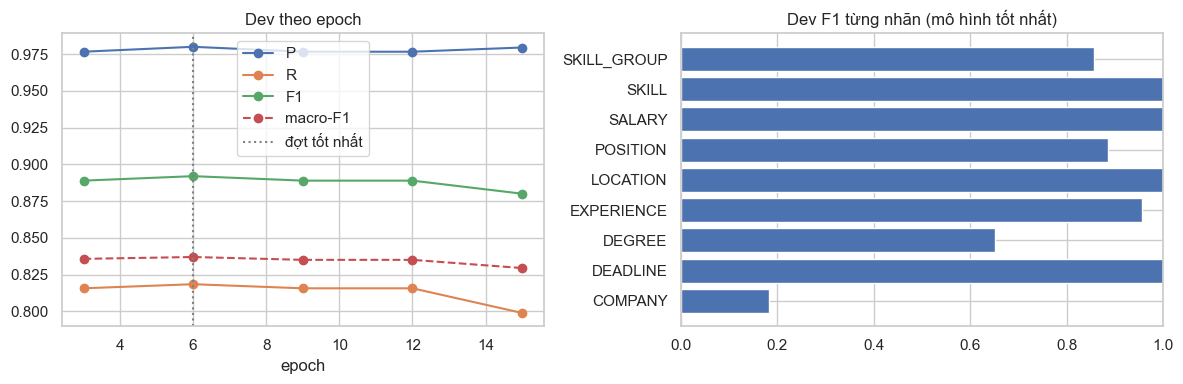

In [18]:
with open(r".\trained_model\lich_su_train.json", encoding="utf-8") as f:
    d = json.load(f)
ls = d["lich_su"]
dot_tot = d["dot_tot_nhat"]
epoch_tot = next(x["epoch"] for x in ls if x["dot"] == dot_tot)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ep = [x["epoch"] for x in ls]
ax[0].plot(ep, [x["dev_p"] for x in ls], marker="o", label="P")
ax[0].plot(ep, [x["dev_r"] for x in ls], marker="o", label="R")
ax[0].plot(ep, [x["dev_f1"] for x in ls], marker="o", label="F1")
ax[0].plot(ep, [x["dev_macro_f1"] for x in ls], marker="o", linestyle="--", label="macro-F1")
ax[0].axvline(epoch_tot, color="gray", linestyle=":", label="đợt tốt nhất")
ax[0].set_title("Dev theo epoch"); ax[0].set_xlabel("epoch"); ax[0].legend()

tn = d["ket_qua_dev_tot_nhat"]["tung_nhan"]
nhan = list(tn)
ax[1].barh(nhan, [tn[n]["f1"] for n in nhan])
ax[1].set_xlim(0, 1); ax[1].set_title("Dev F1 từng nhãn (mô hình tốt nhất)")

plt.tight_layout()
plt.savefig(r".\trained_model\bieu_do_train.png", dpi=150)
plt.show()

### Lưu và nạp lại mô hình



In [19]:
crf.luu_mo_hinh(MODEL_PATH_CRF)
print("Đã lưu:", MODEL_PATH_CRF)


Đã lưu mô hình thành công vào: ./trained_model/crf_model.npz
Đã lưu: ./trained_model/crf_model.npz


## Train mô hình HMM 

In [15]:
hmm = mh.HMM_NER(smoothing=1e-8)
hmm.fit([{"tokenized": X_train_2, "bio": Y_train_2}])
print(f"Đã train: {len(hmm.tags)} nhãn, vocab = {len(hmm.vocab)} từ")

MODEL_PATH = "./trained_model/hmm_model.pkl"
with open(MODEL_PATH, "wb") as f:
    pickle.dump(hmm, f)
print("Đã lưu:", MODEL_PATH)

Đã train: 21 nhãn, vocab = 4763 từ
Đã lưu: ./trained_model/hmm_model.pkl
